In [1]:
import torch
import torch.nn as nn
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
import torch.optim as optim
from torch.optim import lr_scheduler
import matplotlib.pyplot as plt
import os

from network.models import model_selection

In [ ]:
train_path = r"C:\bunny\Deepfake-Detection\data\Dataset\Train"
val_path   = r"C:\bunny\Deepfake-Detection\data\Dataset\Validation"

output_path = "./output/image_xception"
os.makedirs(output_path, exist_ok=True)

batch_size = 32
epochs = 10

In [ ]:
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset
import random

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

full_train_dataset = ImageFolder(train_path, transform=transform)
full_val_dataset   = ImageFolder(val_path, transform=transform)

train_real_indices = [i for i, (_, label) in enumerate(full_train_dataset.samples) if label == 0]
train_fake_indices = [i for i, (_, label) in enumerate(full_train_dataset.samples) if label == 1]

random.shuffle(train_real_indices)
random.shuffle(train_fake_indices)

selected_train_indices = train_real_indices[:5000] + train_fake_indices[:5000]
random.shuffle(selected_train_indices)

train_dataset = Subset(full_train_dataset, selected_train_indices)

val_real_indices = [i for i, (_, label) in enumerate(full_val_dataset.samples) if label == 0]
val_fake_indices = [i for i, (_, label) in enumerate(full_val_dataset.samples) if label == 1]

random.shuffle(val_real_indices)
random.shuffle(val_fake_indices)

selected_val_indices = val_real_indices[:500] + val_fake_indices[:500]
random.shuffle(selected_val_indices)

val_dataset = Subset(full_val_dataset, selected_val_indices)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print("Classes:", full_train_dataset.classes)
print("Train samples used:", len(train_dataset))
print("Validation samples used:", len(val_dataset))

Classes: ['Fake', 'Real']
Train samples used: 10000
Validation samples used: 1000


In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model_selection(modelname='resnet18', num_out_classes=2, dropout=0.5)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)

In [18]:
train_losses = []
train_accs = []
val_accs = []

best_acc = 0

for epoch in range(epochs):
    print(f"Epoch {epoch+1}/{epochs}")
    
    model.train()
    running_loss = 0
    correct = 0
    total = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    
    train_loss = running_loss / len(train_loader)
    train_acc = correct / total
    
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    
    # Validation
    model.eval()
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    
    val_acc = correct / total
    val_accs.append(val_acc)
    
    print(f"Val Acc: {val_acc:.4f}")
    
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), os.path.join(output_path, "best.pkl"))
    
    scheduler.step()

print("Best Val Acc:", best_acc)

Epoch 1/10
Train Loss: 0.2257 | Train Acc: 0.9130
Val Acc: 0.9410
Epoch 2/10
Train Loss: 0.1193 | Train Acc: 0.9533
Val Acc: 0.9210
Epoch 3/10
Train Loss: 0.1040 | Train Acc: 0.9596
Val Acc: 0.8190
Epoch 4/10
Train Loss: 0.0826 | Train Acc: 0.9668
Val Acc: 0.9520
Epoch 5/10
Train Loss: 0.0627 | Train Acc: 0.9761
Val Acc: 0.9490
Epoch 6/10
Train Loss: 0.0307 | Train Acc: 0.9873
Val Acc: 0.9110
Epoch 7/10
Train Loss: 0.0246 | Train Acc: 0.9903
Val Acc: 0.9340
Epoch 8/10
Train Loss: 0.0196 | Train Acc: 0.9912
Val Acc: 0.9580
Epoch 9/10
Train Loss: 0.0302 | Train Acc: 0.9901
Val Acc: 0.9470
Epoch 10/10
Train Loss: 0.0213 | Train Acc: 0.9905
Val Acc: 0.9290
Best Val Acc: 0.958


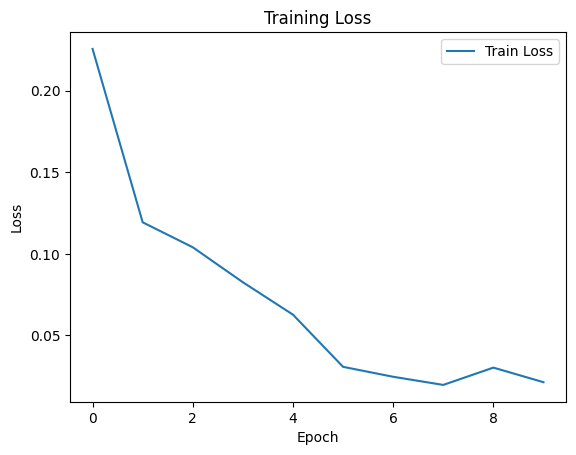

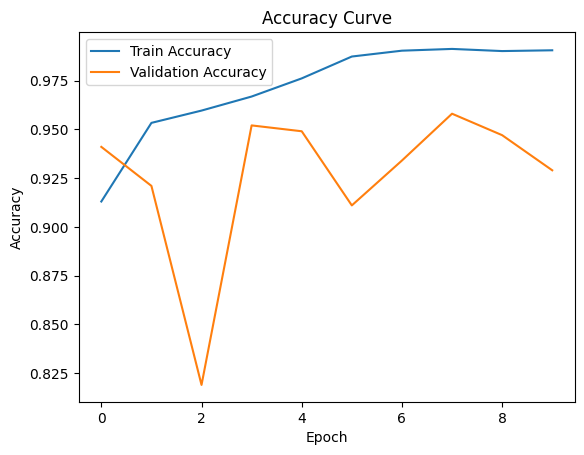

In [19]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training Loss")
plt.show()

plt.figure()
plt.plot(train_accs, label="Train Accuracy")
plt.plot(val_accs, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy Curve")
plt.show()

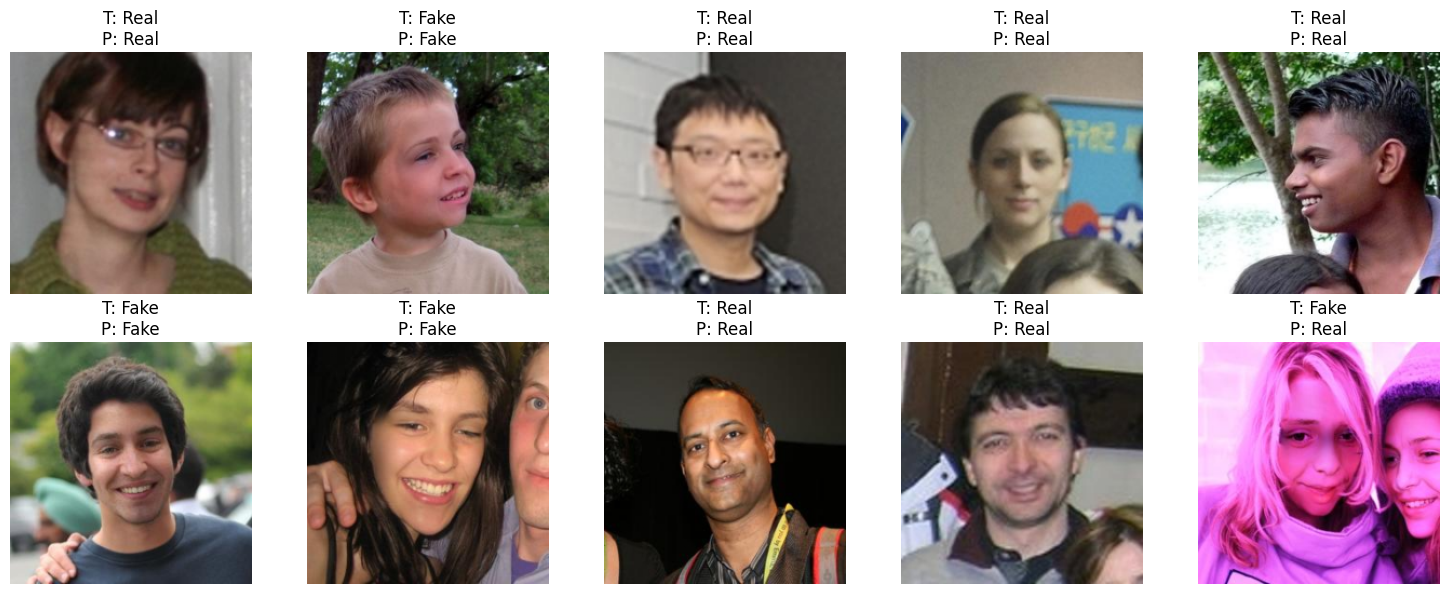

In [ ]:
import random
import matplotlib.pyplot as plt

model.eval()

random_indices = random.sample(range(len(val_dataset)), 10)

plt.figure(figsize=(15, 6))

for i, idx in enumerate(random_indices):
    img, true_label = val_dataset[idx]
    
    with torch.no_grad():
        input_img = img.unsqueeze(0).to(device)
        output = model(input_img)
        pred_label = output.argmax(dim=1).item()

    plt.subplot(2, 5, i+1)
    plt.imshow(img.permute(1, 2, 0))
    plt.title(f"T: {val_dataset.dataset.classes[true_label]}\nP: {val_dataset.dataset.classes[pred_label]}")
    plt.axis("off")

plt.tight_layout()
plt.show()